# Implementation and Time Analysis of the 0/1 Knapsack Problem using Dynamic Programming

**Problem:** Given `n` items, each with a `weight` and a `value`, and a knapsack
with a maximum weight capacity `W`, choose a subset of items to put in the
knapsack such that:
- The total weight does not exceed `W`
- The total value is **maximized**

Each item can be taken **at most once** (this is the "0/1" knapsack — you either
take an item whole or not at all; no fractional items, no repeats).

This notebook covers:
- A naive recursive (brute-force) solution, to show why DP is needed
- A **Dynamic Programming (bottom-up tabulation)** solution using a 2D table
- Reconstructing *which* items were actually chosen (not just the max value)
- A space-optimized 1D DP version
- User input (enter your own item weights, values, and capacity)
- Runtime measurement, time complexity, and space complexity
- A runtime comparison between naive recursion and DP


In [1]:
# Common imports used throughout the notebook
import time
import sys
import matplotlib.pyplot as plt

sys.setrecursionlimit(10000)

def get_user_items(demo_weights=None, demo_values=None):
    """Takes comma-separated weights and values for the items.

    - Interactive use: call with NO arguments to be prompted for both.
    - Notebook demo cells pass fixed strings so the notebook runs end-to-end
      with baked-in outputs. Remove the arguments to type your own items.
    """
    raw_w = demo_weights if demo_weights is not None else input(
        "Enter item weights separated by commas (e.g., 2,3,4,5): "
    )
    raw_v = demo_values if demo_values is not None else input(
        "Enter item values separated by commas (e.g., 3,4,5,6): "
    )
    try:
        weights = [int(x.strip()) for x in raw_w.split(',') if x.strip() != '']
        values = [int(x.strip()) for x in raw_v.split(',') if x.strip() != '']
        if len(weights) != len(values) or not weights:
            raise ValueError
    except ValueError:
        print("Invalid or mismatched input detected, using default items instead.")
        weights = [2, 3, 4, 5]
        values = [3, 4, 5, 6]
    return weights, values


def get_user_capacity(demo_value=None):
    """Takes the knapsack's maximum weight capacity."""
    raw = demo_value if demo_value is not None else input("Enter the knapsack capacity: ")
    try:
        capacity = int(raw)
        if capacity < 0:
            raise ValueError
    except ValueError:
        print("Invalid input detected, defaulting capacity to 5.")
        capacity = 5
    return capacity


## 1. Naive Recursive Solution

For each item, we have exactly two choices: **include it** (if it fits) or
**exclude it**. Trying both choices for every item and taking the better
result gives the brute-force solution.


In [2]:
def knapsack_recursive(weights, values, capacity, i=0):
    """Returns the maximum value achievable using items[i:] within `capacity`."""
    # Base case: no items left, or no capacity left
    if i == len(weights) or capacity == 0:
        return 0

    # Option 1: skip this item
    best = knapsack_recursive(weights, values, capacity, i + 1)

    # Option 2: take this item, if it fits
    if weights[i] <= capacity:
        take = values[i] + knapsack_recursive(weights, values, capacity - weights[i], i + 1)
        best = max(best, take)

    return best


In [3]:
# --- Naive Recursive: quick demo ---
demo_weights = [2, 3, 4, 5]
demo_values = [3, 4, 5, 6]
demo_capacity = 5

result = knapsack_recursive(demo_weights, demo_values, demo_capacity)
print(f"Weights = {demo_weights}, Values = {demo_values}, Capacity = {demo_capacity}")
print(f"Naive Recursive -> Max value: {result}")


Weights = [2, 3, 4, 5], Values = [3, 4, 5, 6], Capacity = 5
Naive Recursive -> Max value: 7


**Time Complexity:** `O(2^n)` — each of the `n` items branches into 2 recursive
calls (include / exclude), giving a full binary recursion tree in the worst case.

**Space Complexity:** `O(n)` — the maximum depth of the recursion call stack.

This re-computes the same `(i, capacity)` sub-problems many times through
different paths in the recursion tree — exactly the kind of **overlapping
subproblems** that dynamic programming is designed to eliminate.


## 2. Dynamic Programming (Bottom-Up, 2D Table)

Build a table `dp[i][w]` = the maximum value achievable using the first `i`
items with a knapsack capacity of `w`.

**Recurrence:**
- If item `i` doesn't fit (`weight[i-1] > w`): `dp[i][w] = dp[i-1][w]` (must skip it)
- Otherwise: `dp[i][w] = max( dp[i-1][w],  values[i-1] + dp[i-1][w - weights[i-1]] )`
  (best of skipping it vs taking it)

The answer to the whole problem is `dp[n][W]`.


In [4]:
def knapsack_dp(weights, values, capacity):
    n = len(weights)
    # dp[i][w] = max value using first i items with capacity w
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        weight_i = weights[i - 1]
        value_i = values[i - 1]
        for w in range(capacity + 1):
            dp[i][w] = dp[i - 1][w]  # start by assuming we skip item i
            if weight_i <= w:
                dp[i][w] = max(dp[i][w], value_i + dp[i - 1][w - weight_i])

    return dp[n][capacity], dp


In [5]:
def reconstruct_chosen_items(weights, values, capacity, dp):
    """Traces back through the dp table to find which items were selected."""
    n = len(weights)
    w = capacity
    chosen = []

    for i in range(n, 0, -1):
        # If the value changed compared to using one fewer item, item i-1 was taken
        if dp[i][w] != dp[i - 1][w]:
            chosen.append(i - 1)   # index of the item taken
            w -= weights[i - 1]

    chosen.reverse()
    return chosen


In [6]:
# --- Dynamic Programming: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_items() / get_user_capacity(),
# to type your own weights, values, and capacity interactively.
weights, values = get_user_items("2,3,4,5", "3,4,5,6")
capacity = get_user_capacity("5")

print("Weights  :", weights)
print("Values   :", values)
print("Capacity :", capacity)

start = time.time()
max_value_recursive = knapsack_recursive(weights, values, capacity)
end = time.time()
print(f"\nNaive Recursive -> Max value: {max_value_recursive}  |  Runtime: {(end - start) * 1000:.4f} ms")

start = time.time()
max_value_dp, dp_table = knapsack_dp(weights, values, capacity)
end = time.time()
print(f"Dynamic Programming -> Max value: {max_value_dp}  |  Runtime: {(end - start) * 1000:.4f} ms")

chosen_indices = reconstruct_chosen_items(weights, values, capacity, dp_table)
print(f"\nItems chosen (by index): {chosen_indices}")
for idx in chosen_indices:
    print(f"  Item {idx}: weight = {weights[idx]}, value = {values[idx]}")
total_weight = sum(weights[i] for i in chosen_indices)
total_value = sum(values[i] for i in chosen_indices)
print(f"Total weight used: {total_weight} / {capacity}")
print(f"Total value      : {total_value}")


Weights  : [2, 3, 4, 5]
Values   : [3, 4, 5, 6]
Capacity : 5

Naive Recursive -> Max value: 7  |  Runtime: 0.0362 ms
Dynamic Programming -> Max value: 7  |  Runtime: 0.0572 ms

Items chosen (by index): [0, 1]
  Item 0: weight = 2, value = 3
  Item 1: weight = 3, value = 4
Total weight used: 5 / 5
Total value      : 7


**Time Complexity:** `O(n * W)` — the table has `(n+1) * (W+1)` cells, and each
cell is filled in `O(1)` time.

**Space Complexity:** `O(n * W)` — for the full 2D `dp` table. (Needed here so we
can reconstruct *which* items were chosen, not just the max value.)

`n * W` is called **pseudo-polynomial** time: it's polynomial in the *numeric
value* of `W`, but `W` itself can require exponentially many bits to represent,
so this is not truly polynomial in the input *size*. In practice, for reasonable
capacities it is extremely fast compared to the naive `O(2^n)` recursion.


## 3. Space-Optimized Dynamic Programming (1D Array)

If you only need the **maximum value** (not the list of chosen items), the 2D
table can be collapsed into a single 1D array of size `capacity + 1`, since each
row of the table only ever depends on the row directly above it.

**Important:** the inner loop over `w` must go **right to left** (from
`capacity` down to `weights[i]`). This ensures that when we update `dp[w]` using
`dp[w - weight]`, we're reading a value that hasn't been updated yet for the
current item — otherwise we'd accidentally allow using the same item twice.


In [7]:
def knapsack_dp_optimized(weights, values, capacity):
    dp = [0] * (capacity + 1)

    for i in range(len(weights)):
        weight_i = weights[i]
        value_i = values[i]
        for w in range(capacity, weight_i - 1, -1):   # right to left!
            dp[w] = max(dp[w], value_i + dp[w - weight_i])

    return dp[capacity]


In [8]:
# --- Verify the space-optimized version matches the 2D version ---
optimized_result = knapsack_dp_optimized(weights, values, capacity)
print(f"2D DP result           : {max_value_dp}")
print(f"Space-optimized result : {optimized_result}")
print("Match!" if optimized_result == max_value_dp else "MISMATCH!")


2D DP result           : 7
Space-optimized result : 7
Match!


**Time Complexity:** `O(n * W)` — same as the 2D version.

**Space Complexity:** `O(W)` — only one array of size `capacity + 1` is kept in
memory at a time, a significant improvement over the 2D table's `O(n * W)` when
only the maximum value (not the chosen items) is needed.


## Runtime Comparison: Naive Recursion vs Dynamic Programming

The cell below times naive recursion against 2D DP as the number of items `n`
grows (capacity held fixed). Since the naive version is exponential in `n`, only
modestly-sized values of `n` are used — larger `n` would take far too long.


In [9]:
# --- Compare naive recursion vs DP as the number of items grows ---
import random
random.seed(42)

capacity_for_comparison = 50
item_counts = [5, 10, 15, 18, 20]

recursive_times = []
dp_times = []

for n in item_counts:
    w = [random.randint(1, 15) for _ in range(n)]
    v = [random.randint(1, 20) for _ in range(n)]

    start = time.time()
    knapsack_recursive(w, v, capacity_for_comparison)
    recursive_times.append((time.time() - start) * 1000)

    start = time.time()
    knapsack_dp(w, v, capacity_for_comparison)
    dp_times.append((time.time() - start) * 1000)

print(f"{'n (items)':<12}{'Recursive (ms)':<18}{'DP (ms)':<12}")
for n, rt, dt in zip(item_counts, recursive_times, dp_times):
    print(f"{n:<12}{rt:<18.4f}{dt:<12.4f}")


n (items)   Recursive (ms)    DP (ms)     
5           0.0129            0.0434      
10          0.6959            0.1092      
15          4.6260            0.1738      
18          17.3800           0.1523      
20          19.3841           0.1652      


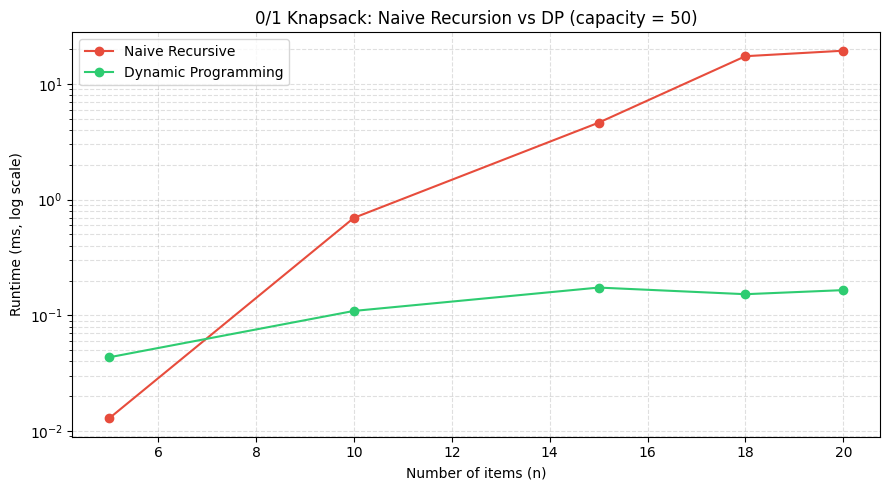

In [10]:
# --- Line chart (log scale on y-axis) ---
plt.figure(figsize=(9, 5))
plt.plot(item_counts, recursive_times, marker='o', label='Naive Recursive', color='#e74c3c')
plt.plot(item_counts, dp_times, marker='o', label='Dynamic Programming', color='#2ecc71')
plt.yscale('log')
plt.xlabel("Number of items (n)")
plt.ylabel("Runtime (ms, log scale)")
plt.title(f"0/1 Knapsack: Naive Recursion vs DP (capacity = {capacity_for_comparison})")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Approach                         | Time Complexity | Space Complexity | Can Reconstruct Chosen Items? |
|-----------------------------------|-------------------|---------------------|----------------------------------|
| Naive Recursive                   | O(2^n)             | O(n) (call stack)   | Yes (with extra bookkeeping)     |
| DP — 2D Tabulation                 | O(n × W)           | O(n × W)            | Yes (via backtracking)           |
| DP — 1D Space-Optimized            | O(n × W)           | O(W)                | No (max value only)              |

Where `n` = number of items, `W` = knapsack capacity.

**Notes:**
- The 0/1 Knapsack problem has **optimal substructure** (the best solution for `n` items and capacity `W` is built from solutions to smaller sub-problems) and **overlapping subproblems** (the same `(i, w)` states are needed repeatedly) — the two hallmarks of a dynamic programming problem.
- Use the **2D table** when you need to know *which* items were chosen, not just the total value.
- Use the **1D space-optimized** version when you only need the maximum achievable value and want to save memory — critical for large capacities.
- This is the **0/1** knapsack (each item used at most once). The **Fractional Knapsack** (where items can be split) is a different problem solved optimally by a greedy algorithm instead of DP, and the **Unbounded Knapsack** (unlimited copies of each item) uses a DP recurrence similar to the Coin Change problem.
